In [1]:
import pandas as pd 
import time 
import matplotlib.pyplot as plt 
from sklearn.preprocessing import StandardScaler 
from sklearn.cluster import KMeans 
from sklearn.decomposition import PCA

In [4]:
df = pd.read_csv("datasets/sales_data_sample.csv", encoding="latin1") 
print("Dataset Preview:") 
print(df.head()) 

Dataset Preview:
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abb

In [5]:
X = df.select_dtypes(include="number").drop( 
columns=["ORDERNUMBER", "ORDERLINENUMBER", "CUSTOMERNUMBER"], 
errors="ignore" 
)

In [6]:
X = X.fillna(X.median()) 

In [7]:
scaler = StandardScaler() 
X_scaled = scaler.fit_transform(X)

In [9]:
inertia = [] 
k_values = range(1, 11) 
start = time.perf_counter() 
for k in k_values: 
    model = KMeans(n_clusters=k, random_state=42, n_init=10) 
    model.fit(X_scaled) 
    inertia.append(model.inertia_)

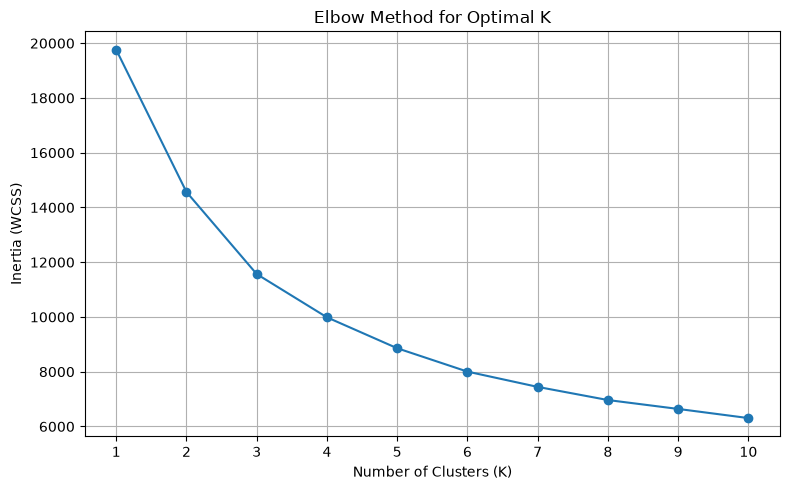

In [10]:
plt.figure(figsize=(8, 5)) 
plt.plot(k_values, inertia, marker="o") 
plt.xlabel("Number of Clusters (K)") 
plt.ylabel("Inertia (WCSS)") 
plt.title("Elbow Method for Optimal K") 
plt.xticks(list(k_values)) 
plt.grid(True) 
plt.tight_layout() 
plt.show()

In [11]:
optimal_k = 4 
model = KMeans( 
n_clusters=optimal_k, random_state=42, n_init=10 
) 
labels = model.fit_predict(X_scaled) 
df["Cluster"] = labels 
end = time.perf_counter() 
print("\nSelected Number of Clusters:", optimal_k) 
print("\nCluster Counts:") 
print(df["Cluster"].value_counts().sort_index())


Selected Number of Clusters: 4

Cluster Counts:
Cluster
0    678
1    950
2    624
3    571
Name: count, dtype: int64


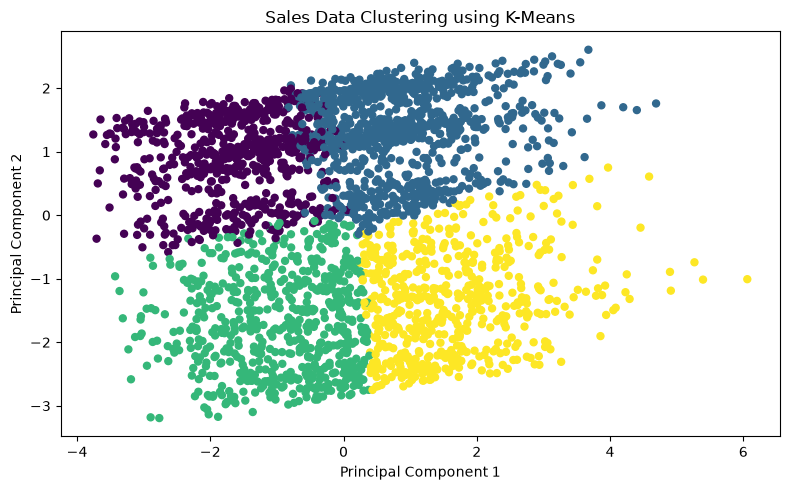

In [12]:
pca = PCA(n_components=2) 
reduced_data = pca.fit_transform(X_scaled) 
plt.figure(figsize=(8, 5)) 
plt.scatter( 
reduced_data[:, 0], reduced_data[:, 1], 
c=labels, cmap="viridis", s=25 
) 
plt.xlabel("Principal Component 1") 
plt.ylabel("Principal Component 2") 
plt.title("Sales Data Clustering using K-Means") 
plt.tight_layout() 
plt.show() 